In [1]:
print("hello")

hello


1) Dataset exploration

2) Loan status distribution

3) Default rate segmentation

4) Numerical feature analysis

5) Outliers, missingness and correlation

6) Final EDA conclusions

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "raw" /
    "accepted_2007_to_2018Q4.csv.gz"
)

print("Dataset exists:", DATA_PATH.exists())

Dataset exists: True


In [3]:
df_sample = pd.read_csv(DATA_PATH, nrows=10)

print("Shape of sample:", df_sample.shape)

display(df_sample.head())

print("\nColumns:")
print(df_sample.columns.tolist())


Shape of sample: (10, 151)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN



Columns:
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_no

In [4]:
df_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Columns: 151 entries, id to settlement_term
dtypes: float64(125), int64(1), str(25)
memory usage: 11.9 KB


In [5]:
# Loan status distribution

from collections import Counter

status_counts = Counter()
total_rows = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["loan_status"],
    chunksize=200_000
):
    status_counts.update(
        chunk["loan_status"].fillna("MISSING").value_counts().to_dict()
    )
    total_rows += len(chunk)

status_df = pd.DataFrame(
    status_counts.items(),
    columns=["loan_status", "loan_count"]
).sort_values("loan_count", ascending=False)

print("Total loan records:", total_rows)

display(status_df)

Total loan records: 2260701


,loan_status,loan_count
0,Fully Paid,1076751
2,Current,878317
1,Charged Off,268559
3,Late (31-120 days),21467
4,In Grace Period,8436
5,Late (16-30 days),4349
8,Does not meet the credit policy. Status:Fully ...,1988
9,Does not meet the credit policy. Status:Charge...,761
6,Default,40
7,MISSING,33


In [6]:
fully_paid = status_counts.get("Fully Paid", 0)
charged_off = status_counts.get("Charged Off", 0)

resolved_loans = fully_paid + charged_off

charge_off_rate = charged_off / resolved_loans

print("Fully Paid:", fully_paid)
print("Charged Off:", charged_off)
print("Resolved loans:", resolved_loans)

print(f"Observed charge-off rate: {charge_off_rate:.2%}")

Fully Paid: 1076751
Charged Off: 268559
Resolved loans: 1345310
Observed charge-off rate: 19.96%


In [7]:
# now we will try to understand which grades or purposes charge off more
# investigating default rate by loan grade and loan purpose

from collections import defaultdict

segment_totals = {
    "grade": defaultdict(lambda: [0, 0]),
    "purpose": defaultdict(lambda: [0, 0])
}

valid_statuses = ["Fully Paid", "Charged Off", "Default"]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["loan_status", "grade", "purpose"],
    chunksize=200_000
):

    # Keep loans with resolved outcomes
    chunk = chunk[chunk["loan_status"].isin(valid_statuses)].copy()

    # Define binary target
    chunk["default_flag"] = (
        chunk["loan_status"].isin(["Charged Off", "Default"])
    ).astype(int)

    # Aggregate both dimensions
    for col in ["grade", "purpose"]:

        grouped = chunk.groupby(col, dropna=False)["default_flag"].agg(
            loan_count="count",
            defaults="sum"
        )

        for category, row in grouped.iterrows():

            category = (
                "Missing" if pd.isna(category) else str(category)
            )

            segment_totals[col][category][0] += row["loan_count"]
            segment_totals[col][category][1] += row["defaults"]


# Build summary tables
for col in ["grade", "purpose"]:

    result = pd.DataFrame([
        {
            col: category,
            "loan_count": values[0],
            "defaults": values[1],
            "default_rate": values[1] / values[0]
        }
        for category, values in segment_totals[col].items()
    ])

    result = result.sort_values("default_rate", ascending=False)

    print(f"\nDefault rate by {col.upper()}")
    display(result)

    if col == "grade":
        grade_df = result.copy()
    else:
        purpose_df = result.copy()


Default rate by GRADE


,grade,loan_count,defaults,default_rate
6,G,9132,4560,0.499343
5,F,32059,14492,0.452042
4,E,93656,36041,0.384823
3,D,200966,61067,0.303867
2,C,381694,85657,0.224413
1,B,392748,52576,0.133867
0,A,235095,14206,0.060427



Default rate by PURPOSE


,purpose,loan_count,defaults,default_rate
10,small_business,15416,4580,0.297094
9,renewable_energy,933,221,0.236870
7,moving,9480,2214,0.233544
4,house,7254,1588,0.218914
6,medical,15556,3389,0.217858
2,debt_consolidation,780342,165035,0.211491
8,other,77877,16387,0.210422
11,vacation,9065,1738,0.191726
5,major_purchase,29427,5475,0.186054
3,home_improvement,87507,15505,0.177186


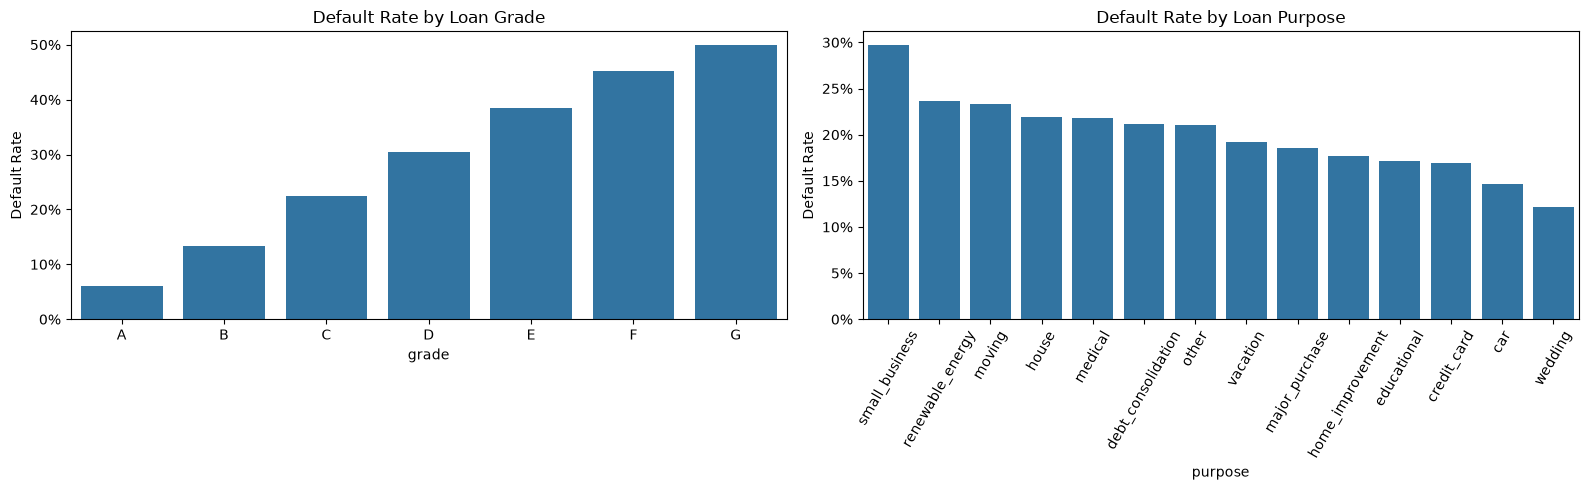

In [10]:
# visualizing these defaulters results

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

grade_plot = grade_df.sort_values("grade")

sns.barplot(
    data=grade_plot,
    x="grade",
    y="default_rate",
    ax=axes[0]
)

axes[0].set_title("Default Rate by Loan Grade")
axes[0].set_ylabel("Default Rate")
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

purpose_plot = purpose_df.sort_values(
    "default_rate",
    ascending=False
)

sns.barplot(
    data=purpose_plot,
    x="purpose",
    y="default_rate",
    ax=axes[1]
)

axes[1].set_title("Default Rate by Loan Purpose")
axes[1].set_ylabel("Default Rate")
axes[1].tick_params(axis="x", rotation=60)
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

plt.tight_layout()
plt.show()

Does annual income have a relationship with default?

Does a higher debt-to-income ratio indicate greater credit risk?

What about interest rates and credit scores?

In [11]:
eda_cols = [
    "loan_status",
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "fico_range_low"
]

valid_statuses = ["Fully Paid", "Charged Off", "Default"]

samples = []
missing_counts = pd.Series(0, index=eda_cols[1:], dtype="int64")
resolved_total = 0

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=eda_cols,
        chunksize=200_000
    )
):
    chunk = chunk[
        chunk["loan_status"].isin(valid_statuses)
    ].copy()

    resolved_total += len(chunk)

    # Track missing values using the full eligible population
    missing_counts += chunk[eda_cols[1:]].isna().sum()

    chunk["default_flag"] = (
        chunk["loan_status"].isin(
            ["Charged Off", "Default"]
        )
    ).astype(int)

    # Take a manageable random sample per chunk
    samples.append(
        chunk.sample(
            n=min(5000, len(chunk)),
            random_state=42 + i
        )
    )

eda_sample = pd.concat(samples, ignore_index=True)

print("Resolved population:", resolved_total)
print("EDA sample size:", len(eda_sample))

Resolved population: 1345350
EDA sample size: 60000


In [12]:
# missing value analysis

missing_df = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (
        missing_counts / resolved_total * 100
    )
}).sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_df)

,missing_count,missing_percentage
dti,374,0.027799
loan_amnt,0,0.000000
annual_inc,0,0.000000
int_rate,0,0.000000
fico_range_low,0,0.000000


In [13]:
eda_sample["outcome"] = eda_sample["default_flag"].map({
    0: "Fully Paid",
    1: "Default"
})

features = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "fico_range_low"
]

summary = eda_sample.groupby("outcome")[features].agg(
    ["mean", "median"]
)

display(summary.round(2))

loan_amnt          annual_inc            dti        int_rate  \
                mean   median       mean   median  mean median     mean   
outcome                                                                   
Default     15648.43  14075.0   71184.42  60000.0  20.3  19.73    15.87   
Fully Paid  14109.07  12000.0   78143.30  65800.0  18.0  17.11    12.76   

                  fico_range_low         
           median           mean median  
outcome                                  
Default     15.05         688.79  680.0  
Fully Paid  12.13         699.74  690.0

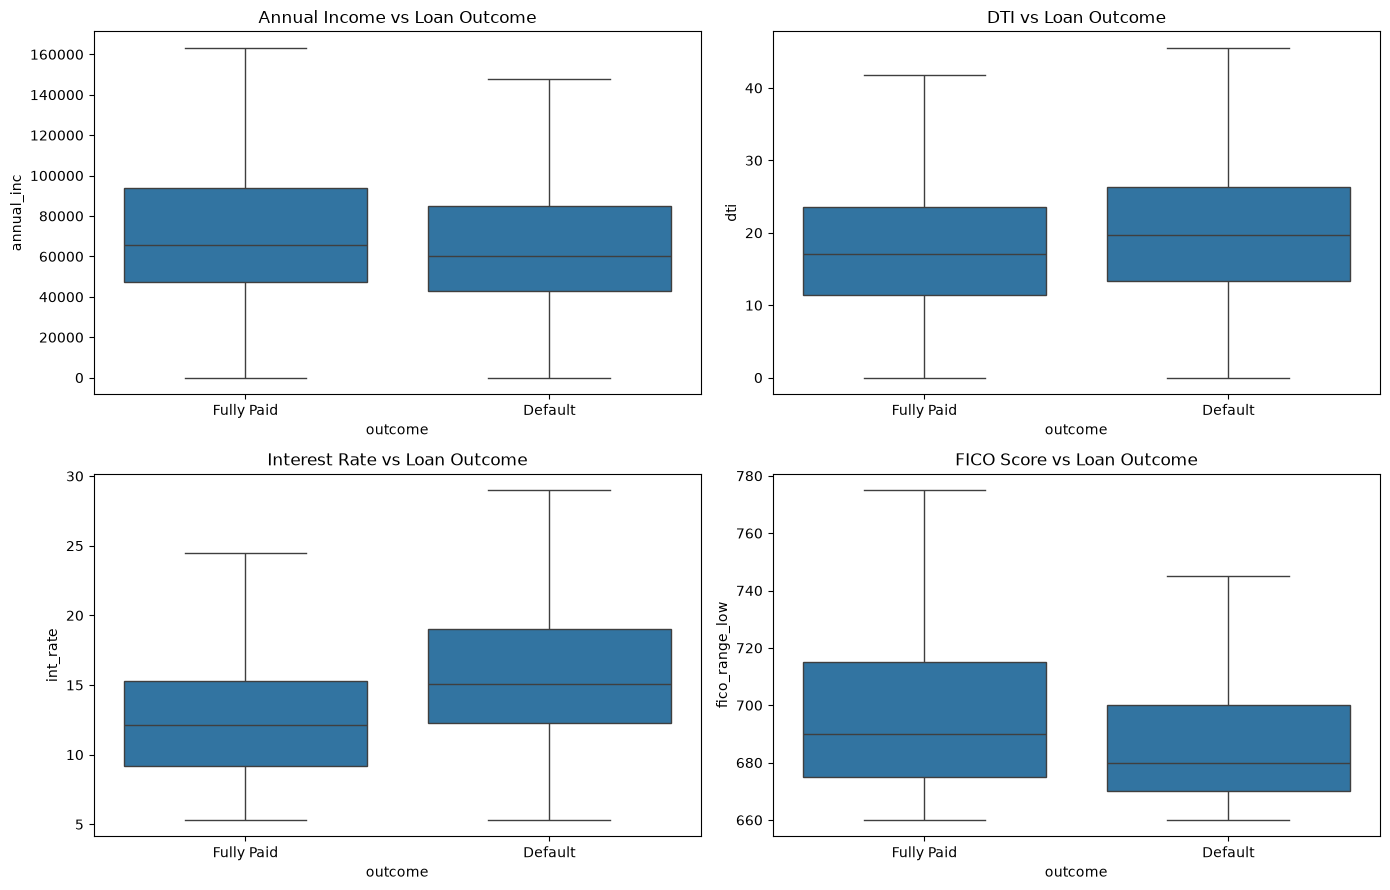

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(
    data=eda_sample,
    x="outcome",
    y="annual_inc",
    ax=axes[0, 0],
    showfliers=False
)
axes[0, 0].set_title("Annual Income vs Loan Outcome")

sns.boxplot(
    data=eda_sample,
    x="outcome",
    y="dti",
    ax=axes[0, 1],
    showfliers=False
)
axes[0, 1].set_title("DTI vs Loan Outcome")

sns.boxplot(
    data=eda_sample,
    x="outcome",
    y="int_rate",
    ax=axes[1, 0],
    showfliers=False
)
axes[1, 0].set_title("Interest Rate vs Loan Outcome")

sns.boxplot(
    data=eda_sample,
    x="outcome",
    y="fico_range_low",
    ax=axes[1, 1],
    showfliers=False
)
axes[1, 1].set_title("FICO Score vs Loan Outcome")

plt.tight_layout()
plt.show()

now lets see if there are any monotonic patterns wrg dti and defaults

In [15]:
numeric_features = [
    "annual_inc",
    "dti",
    "fico_range_low",
    "loan_amnt"
]

for col in numeric_features:

    temp = eda_sample[[col, "default_flag"]].dropna().copy()

    # Divide the feature into five quantile-based groups
    temp["segment"] = pd.qcut(
        temp[col],
        q=5,
        duplicates="drop"
    )

    result = temp.groupby(
        "segment",
        observed=True
    ).agg(
        loan_count=("default_flag", "count"),
        defaults=("default_flag", "sum"),
        default_rate=("default_flag", "mean")
    )

    print(f"\nDefault rate by {col}")
    display(result)


Default rate by annual_inc


,loan_count,defaults,default_rate
segment,,,
"(-0.001, 42000.0]",12174,2930,0.240677
"(42000.0, 58000.0]",12283,2610,0.212489
"(58000.0, 75000.0]",12893,2626,0.203676
"(75000.0, 100000.0]",11205,2100,0.187416
"(100000.0, 3098500.0]",11445,1851,0.161730



Default rate by dti


,loan_count,defaults,default_rate
segment,,,
"(-0.001, 10.398]",11991,1879,0.156701
"(10.398, 15.27]",11992,2016,0.168112
"(15.27, 20.04]",12023,2326,0.193463
"(20.04, 25.8]",11960,2659,0.222324
"(25.8, 999.0]",11989,3229,0.269330



Default rate by fico_range_low


,loan_count,defaults,default_rate
segment,,,
"(659.999, 670.0]",15396,3996,0.259548
"(670.0, 680.0]",9034,2150,0.237990
"(680.0, 700.0]",14414,3043,0.211114
"(700.0, 720.0]",9809,1655,0.168723
"(720.0, 845.0]",11347,1273,0.112188



Default rate by loan_amnt


,loan_count,defaults,default_rate
segment,,,
"(999.999, 6025.0]",12016,1923,0.160037
"(6025.0, 10000.0]",13455,2431,0.180676
"(10000.0, 15000.0]",12092,2552,0.211049
"(15000.0, 21350.0]",10443,2349,0.224935
"(21350.0, 40000.0]",11994,2862,0.238619


In [16]:
# Our original sampling code selected 5,000 observations from every chunk. 
# Since the final chunk is smaller, that overrepresents the final chunk in our EDA sample.

samples = []

sample_cols = [
    "loan_status",
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "fico_range_low"
]

for i, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=sample_cols,
        chunksize=200_000
    )
):
    chunk = chunk[
        chunk["loan_status"].isin(
            ["Fully Paid", "Charged Off", "Default"]
        )
    ].copy()

    chunk["default_flag"] = (
        chunk["loan_status"].isin(
            ["Charged Off", "Default"]
        )
    ).astype(int)

    # Same sampling fraction for every chunk
    samples.append(
        chunk.sample(
            frac=0.045,
            random_state=42 + i
        )
    )

eda_sample = pd.concat(samples, ignore_index=True)

print("Corrected EDA sample:", len(eda_sample))

Corrected EDA sample: 60542


In [17]:
print("DTI >= 100:", (eda_sample["dti"] >= 100).sum())
print("DTI == 999:", (eda_sample["dti"] == 999).sum())

print("Annual income <= 0:",
      (eda_sample["annual_inc"] <= 0).sum())

print("Annual income > 1 million:",
      (eda_sample["annual_inc"] > 1_000_000).sum())

display(
    eda_sample.loc[
        (eda_sample["dti"] >= 100) |
        (eda_sample["annual_inc"] > 1_000_000),
        ["annual_inc", "dti", "default_flag"]
    ].head(20)
)

DTI >= 100: 22
DTI == 999: 4
Annual income <= 0: 25
Annual income > 1 million: 16


,annual_inc,dti,default_flag
380,1101000.00,4.00,0
1209,3000000.00,0.19,1
2084,8700.00,120.66,0
3090,1200000.00,1.10,0
3152,1500000.00,2.48,0
5608,4300000.00,0.04,0
5943,1100000.00,1.72,0
7124,4000095.00,0.25,0
8356,1700000.00,3.03,0
15136,1500006.00,2.01,1


In [18]:
# some data cleaning required here lol

eda_clean = eda_sample.copy()

# Invalid income values
eda_clean.loc[
    eda_clean["annual_inc"] <= 0, "annual_inc"
] = np.nan

# Suspicious DTI sentinel
eda_clean.loc[
    eda_clean["dti"] == 999, "dti"
] = np.nan

# Inspect updated distributions
display(
    eda_clean[
        ["annual_inc", "dti", "loan_amnt",
         "int_rate", "fico_range_low"]
    ].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).T
)

,count,mean,std,min,1%,5%,50%,95%,99%,max
annual_inc,60517.0,76127.924637,59143.471744,20.00,18000.00,28000.00,65000.00,155000.00,250000.0000,4300000.00
dti,60513.0,18.236716,9.120705,0.00,1.84,5.00,17.62,32.91,38.5488,406.83
loan_amnt,60542.0,14447.474893,8725.874328,1000.00,1500.00,3200.00,12000.00,32898.75,35000.0000,40000.00
int_rate,60542.0,13.242691,4.764767,5.31,5.32,6.49,12.74,21.99,26.3000,30.99
fico_range_low,60542.0,696.188018,31.793350,660.00,660.00,660.00,690.00,760.00,800.0000,845.00


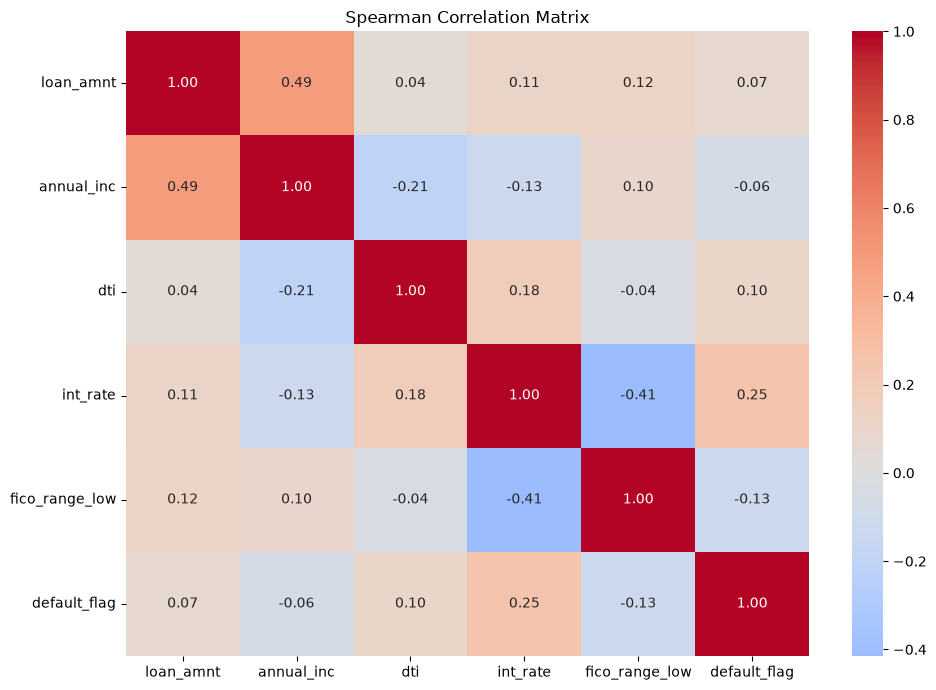

In [19]:
# spearman correlation

corr_features = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "fico_range_low",
    "default_flag"
]

correlation_matrix = eda_clean[
    corr_features
].corr(method="spearman")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [20]:
# A model should be trained using information available at the time the loan was originated.

# Also, our dataset ends in 2018, so loans issued shortly before that date might not have had sufficient time to reach a final outcome.

from collections import defaultdict

vintage_counts = defaultdict(int)
term_counts = defaultdict(int)
date_min = None
date_max = None

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["issue_d", "term", "loan_status"],
    chunksize=200_000
):

    dates = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    date_min = dates.min() if date_min is None else min(date_min, dates.min())
    date_max = dates.max() if date_max is None else max(date_max, dates.max())

    for (year, term), count in (
        chunk.assign(issue_year=dates.dt.year)
        .groupby(["issue_year", "term"])
        .size()
        .items()
    ):
        vintage_counts[(year, term)] += count

print("Earliest origination:", date_min)
print("Latest origination:", date_max)

vintage_df = pd.DataFrame([
    {
        "issue_year": year,
        "term": term,
        "loan_count": count
    }
    for (year, term), count in vintage_counts.items()
])

display(
    vintage_df.sort_values(["issue_year", "term"])
)

Earliest origination: 2007-06-01 00:00:00
Latest origination: 2018-12-01 00:00:00


,issue_year,term,loan_count
10,2007.0,36 months,603
11,2008.0,36 months,2393
12,2009.0,36 months,5281
13,2010.0,36 months,9156
14,2010.0,60 months,3381
15,2011.0,36 months,14101
16,2011.0,60 months,7620
19,2012.0,36 months,43470
20,2012.0,60 months,9897
17,2013.0,36 months,100422


In [21]:
all_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

print("Total features:", len(all_columns))

for i, col in enumerate(all_columns, 1):
    print(f"{i}. {col}")

Total features: 151
1. id
2. member_id
3. loan_amnt
4. funded_amnt
5. funded_amnt_inv
6. term
7. int_rate
8. installment
9. grade
10. sub_grade
11. emp_title
12. emp_length
13. home_ownership
14. annual_inc
15. verification_status
16. issue_d
17. loan_status
18. pymnt_plan
19. url
20. desc
21. purpose
22. title
23. zip_code
24. addr_state
25. dti
26. delinq_2yrs
27. earliest_cr_line
28. fico_range_low
29. fico_range_high
30. inq_last_6mths
31. mths_since_last_delinq
32. mths_since_last_record
33. open_acc
34. pub_rec
35. revol_bal
36. revol_util
37. total_acc
38. initial_list_status
39. out_prncp
40. out_prncp_inv
41. total_pymnt
42. total_pymnt_inv
43. total_rec_prncp
44. total_rec_int
45. total_rec_late_fee
46. recoveries
47. collection_recovery_fee
48. last_pymnt_d
49. last_pymnt_amnt
50. next_pymnt_d
51. last_credit_pull_d
52. last_fico_range_high
53. last_fico_range_low
54. collections_12_mths_ex_med
55. mths_since_last_major_derog
56. policy_code
57. application_type
58. annual_i

#	Feature	Type - our selected features for now for model training
1	loan_amnt	Numerical
2	term	Categorical
3	emp_length	Categorical
4	home_ownership	Categorical
5	annual_inc	Numerical
6	verification_status	Categorical
7	purpose	Categorical
8	dti	Numerical
9	delinq_2yrs	Numerical
10	inq_last_6mths	Numerical
11	open_acc	Numerical
12	pub_rec	Numerical
13	revol_bal	Numerical
14	revol_util	Numerical
15	total_acc	Numerical
16	fico_range_low	Numerical

In [ ]:
# now we need to see any potential missing and outlier values

In [22]:
candidate_features = [
    "loan_amnt",
    "term",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "fico_range_low"
]

audit_columns = candidate_features + [
    "loan_status",
    "issue_d",
    "application_type"
]

missing_counts = pd.Series(0, index=candidate_features)
total_eligible = 0

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=audit_columns,
    chunksize=200_000
):
    chunk = chunk[
        chunk["loan_status"].isin(
            ["Fully Paid", "Charged Off", "Default"]
        )
    ]

    # Count only eligible modelling observations
    missing_counts += chunk[candidate_features].isna().sum()
    total_eligible += len(chunk)

feature_audit = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (
        missing_counts / total_eligible * 100
    ).round(2)
}).sort_values("missing_percentage", ascending=False)

print("Eligible observations:", total_eligible)
display(feature_audit)

Eligible observations: 1345350


,missing_count,missing_percentage
emp_length,78516,5.84
revol_util,857,0.06
dti,374,0.03
term,0,0.00
home_ownership,0,0.00
annual_inc,0,0.00
verification_status,0,0.00
loan_amnt,0,0.00
purpose,0,0.00
delinq_2yrs,0,0.00


In [23]:
quality_counts = {
    "nonpositive_income": 0,
    "dti_999": 0,
    "dti_above_100": 0
}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["loan_status", "annual_inc", "dti"],
    chunksize=200_000
):
    chunk = chunk[
        chunk["loan_status"].isin(
            ["Fully Paid", "Charged Off", "Default"]
        )
    ]

    quality_counts["nonpositive_income"] += (
        chunk["annual_inc"] <= 0
    ).sum()

    quality_counts["dti_999"] += (
        chunk["dti"] == 999
    ).sum()

    quality_counts["dti_above_100"] += (
        chunk["dti"] > 100
    ).sum()

display(pd.Series(quality_counts, name="count"))

nonpositive_income    361
dti_999                38
dti_above_100         533
Name: count, dtype: int64


# Final EDA Conclusions — LendingClub Credit Risk Dataset

## 1. Dataset Overview

- Dataset: LendingClub Accepted Loans (2007–2018 Q4).
- Total records: 2,260,701.
- Total available columns: 151.
- Eligible observations with resolved outcomes: 1,345,350.
- Data includes borrower characteristics, loan details, credit history,
  repayment information and loan performance.

## 2. Target Variable Definition

We define a binary classification target:

- Fully Paid -> 0 (Non-default)
- Charged Off -> 1 (Default)
- Default -> 1 (Default)

Other unresolved or ambiguous loan statuses are excluded initially.

Eligible population:

| Loan Status | Count |
|---|---:|
| Fully Paid | 1,076,751 |
| Charged Off | 268,559 |
| Default | 40 |
| **Total** | **1,345,350** |

The observed default rate is approximately 19.96%.

Note: This is an observed historical outcome rate among selected
resolved loans, not a universal or regulatory PD estimate.

## 3. Portfolio Segmentation Findings

### Loan Grade

Observed default rates increase consistently as LendingClub's
loan grade deteriorates.

- Grade A: 6.04%
- Grade B: 13.39%
- Grade C: 22.44%
- Grade D: 30.39%
- Grade E: 38.48%
- Grade F: 45.20%
- Grade G: 49.93%

This indicates that LendingClub's existing grading system
distinguishes between different historical risk segments.

Grade and sub_grade will be excluded from the initial baseline
model to independently investigate the predictive value of
underlying borrower characteristics.

### Loan Purpose

Default rates vary across loan purposes.

Small-business loans exhibit a relatively high observed default
rate (approximately 29.71%), while wedding loans have a lower
observed rate (approximately 12.16%).

Segment sizes must be considered when interpreting these rates.

These findings are descriptive and do not establish causality.

## 4. Numerical Feature Analysis

Preliminary comparisons between Fully Paid and Default loans
show the following patterns:

| Feature | Fully Paid Median | Default Median |
|---|---:|---:|
| Loan Amount | $12,000 | $14,075 |
| Annual Income | $65,800 | $60,000 |
| DTI | 17.11 | 19.73 |
| Interest Rate | 12.13% | 15.05% |
| FICO Score | 690 | 680 |

Preliminary observations:

- Higher annual income is associated with lower default rates.
- Higher DTI is associated with higher default rates.
- Higher FICO scores are associated with lower default rates.
- Larger loan amounts show higher observed default rates.
- Interest rates are higher among defaulting borrowers, potentially
  reflecting existing lender risk assessments and pricing decisions.

## 5. Numerical Feature Segmentation

Preliminary quantile-based analysis indicated:

- Annual income: default rates generally decrease as income increases.
- DTI: default rates increase with higher debt-to-income ratios.
- FICO: default rates decrease as credit scores improve.
- Loan amount: default rates generally increase with larger loans.

These patterns support retaining the corresponding variables
as candidate predictors.

Note: The initial segmentation and numerical summary were generated
using the earlier approximate per-chunk sample. They should be
recomputed using the corrected proportional EDA sample before
being treated as final descriptive estimates.

## 6. Data Quality Assessment

Full eligible-population checks identified:

| Data Quality Issue | Count |
|---|---:|
| Missing employment length | 78,516 |
| Missing revolving utilization | 857 |
| Missing DTI | 374 |
| Non-positive annual income | 361 |
| DTI equal to 999 | 38 |
| DTI greater than 100 | 533 |

Treatment decisions:

- Employment length: Treat missing values as an Unknown category.
- Revolving utilization: Impute using training-set median.
- DTI: Investigate extreme values and treat 999 as a suspicious
  sentinel value.
- Non-positive annual income: Convert to missing values.
- Annual income outliers: Investigate and consider transformations.
- DTI above 100: Flag and investigate rather than automatically
  remove, as values above 100 can be mathematically valid.

All imputation parameters will be learned from training data only.

## 7. Feature Selection

The initial baseline model will investigate 16 candidate features:

1. loan_amnt
2. term
3. emp_length
4. home_ownership
5. annual_inc
6. verification_status
7. purpose
8. dti
9. delinq_2yrs
10. inq_last_6mths
11. open_acc
12. pub_rec
13. revol_bal
14. revol_util
15. total_acc
16. fico_range_low

Final selection will depend on data availability, predictive
performance and validation results.

Excluded from the initial baseline:

- Identifiers such as id and member_id.
- Existing risk assessments such as grade and sub_grade.
- Interest rate, initially, to avoid relying on LendingClub's
  existing pricing decisions.
- Post-origination information such as recoveries, payments,
  last payment dates and hardship information.
- Loan status, which is used only to construct the target.

Issue date will be retained for temporal splitting rather than
used as an initial predictive feature.

## 8. Dataset and Modelling Limitations

- LendingClub data does not represent Citi's actual loan portfolio.
- The dataset contains accepted/funded loans, introducing
  potential selection bias.
- Historical charge-off outcomes are not automatically equivalent
  to regulatory definitions of default.
- The dataset does not provide everything required for a complete
  regulatory PD, LGD and EAD framework.
- Recent origination vintages may have insufficient observation
  periods.
- Correlations and segmented default rates represent associations,
  not causal relationships.

A time-aware modelling population and validation strategy are
therefore necessary.

## 9. Overall EDA Conclusion

The exploratory analysis identified several potentially
informative borrower and loan characteristics associated with
historical loan default.

DTI, FICO score, annual income and loan amount exhibit useful
risk-related patterns and will be investigated further during
statistical modelling.

The dataset contains sufficient historical observations to build
an educational credit-default prediction system, subject to
careful target definition, feature availability checks, data
preprocessing and temporal validation.

The next phase will focus on:

1. Finalizing the eligible modelling population.
2. Feature engineering and preprocessing.
3. Time-aware train, validation and test splitting.
4. Logistic Regression as the baseline PD model.
5. Advanced model benchmarking.
6. Independent model validation and monitoring.
